# 1. QCNN v1: lectura por probabilidades

Este notebook abre una serie de cuatro sobre una red convolucional cuántica híbrida (QCNN) aplicada a MNIST. La pregunta del estudio es **cuánto aporta la parte cuántica de la red frente a controles clásicos de tamaño parecido**. No se busca demostrar una ventaja cuántica: es un laboratorio en el que la arquitectura evoluciona en tres versiones y, al final, se aísla la contribución del circuito con ablaciones.

| Notebook | Contenido |
| --- | --- |
| **01** | Protocolo común y v1: codificación por parches, QCNN piramidal y lectura por probabilidades |
| 02 | v2: más expresividad en el circuito con la misma lectura |
| 03 | v3: 16 qubits, imagen 16×16 y lectura ⟨Z⟩ con una capa lineal |
| 04 | Ablaciones y comparación final: ¿qué aporta la parte cuántica? |

Los notebooks no entrenan: leen los resultados guardados en `results/` por `scripts/run.py --todas` y los presentan.

## Protocolo común

- **Datos.** MNIST, 2.000 imágenes de entrenamiento y 500 de prueba, estratificadas por clase. La partición es fija (semilla 42) y la misma para todos los modelos. Los píxeles se normalizan a [0, 1] y las imágenes se reducen por interpolación bilineal a 10×10 (v1, v2 y sus controles) o a 16×16 (v3, sus ablaciones y sus controles).
- **Entrenamiento.** Adam con tasa de aprendizaje 0,01, 30 épocas y lotes de 16 para todos los modelos, en precisión doble. No se ajustan hiperparámetros por modelo.
- **Semillas.** Cada configuración se entrena con las semillas 42, 43 y 44, que cambian la inicialización y el orden de los lotes. Se reporta media ± desviación estándar muestral.
- **Métrica.** Accuracy de prueba de la **última época**. No se elige la mejor época: hacerlo sería usar el conjunto de prueba para seleccionar el modelo.
- **Parámetros.** El conteo incluye todas las capas entrenables, clásicas y cuánticas.
- **Simulación.** Exacta y sin ruido, con PennyLane (`default.qubit`) y JAX.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from qcnn_mnist import figuras
from qcnn_mnist import resultados as res

figuras.aplicar_estilo()
R = res.cargar()   # modelo -> resultados por semilla (results/<modelo>/semilla_<s>.json)
S = res.resumen(R) # modelo -> media y desviación entre semillas

## Datos y codificación por parches

Con imágenes de 10×10 y parches de 2×2 hay una rejilla de 5×5 parches. v1 tiene 10 qubits, uno por parche, y usa la **banda central** de la rejilla (filas 1 y 2, parches 5 a 14), que es donde se concentra el trazo; las filas de los bordes son casi todo fondo.

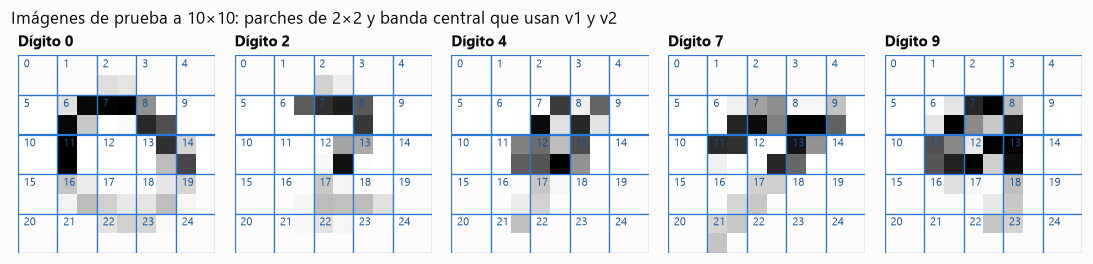

In [2]:
from qcnn_mnist.datos import preparar_datos

datos10 = preparar_datos(10)
indices = [int(np.flatnonzero(datos10.y_test == c)[0]) for c in (0, 2, 4, 7, 9)]

fig, ejes = plt.subplots(1, len(indices), figsize=(10, 2.4))
for ax, i in zip(ejes, indices):
    figuras.rejilla_parches(ax, datos10.x_test[i], 2, usados=range(5, 15), titulo=f"Dígito {datos10.y_test[i]}")
fig.suptitle("Imágenes de prueba a 10×10: parches de 2×2 y banda central que usan v1 y v2", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
figuras.guardar(fig, "01_parches_10x10")
plt.show()

Cada parche $p$ (4 píxeles) se comprime con una capa lineal compartida por todos los parches, $v = Wp + b$, a dos números que se normalizan a un par $(\alpha, \beta)$ de norma 1. Ese par se carga en su qubit con

$$R_Y(\theta)\,|0\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad \theta = 2\,\operatorname{arctan2}(\beta, \alpha).$$

En v1 la matriz $W$ (2×4) es entrenable y el bias $b$ es fijo.

## Circuito de v1

- **Convolución:** una rotación $R_Y$ entrenable por qubit seguida de un anillo de CNOT.
- **Pooling fijo:** una CNOT del qubit descartado al superviviente. La pirámide es 10 → 8 → 4.
- **Lectura por probabilidades:** se miden los 4 qubits finales, que tienen 16 estados base. Los 10 primeros son las clases; los 6 sobrantes (*ghost states*) se penalizan en la pérdida:

$$\mathcal{L} = -\log p_y + \lambda \sum_{k=10}^{15} p_k, \qquad \lambda = 0{,}3.$$

Parámetros entrenables: 8 de la capa de entrada, 10 de la primera convolución y 8 de la segunda, 26 en total. El diagrama usa los parámetros entrenados con la semilla 42; la primera columna de $R_Y$ es la codificación de los parches.

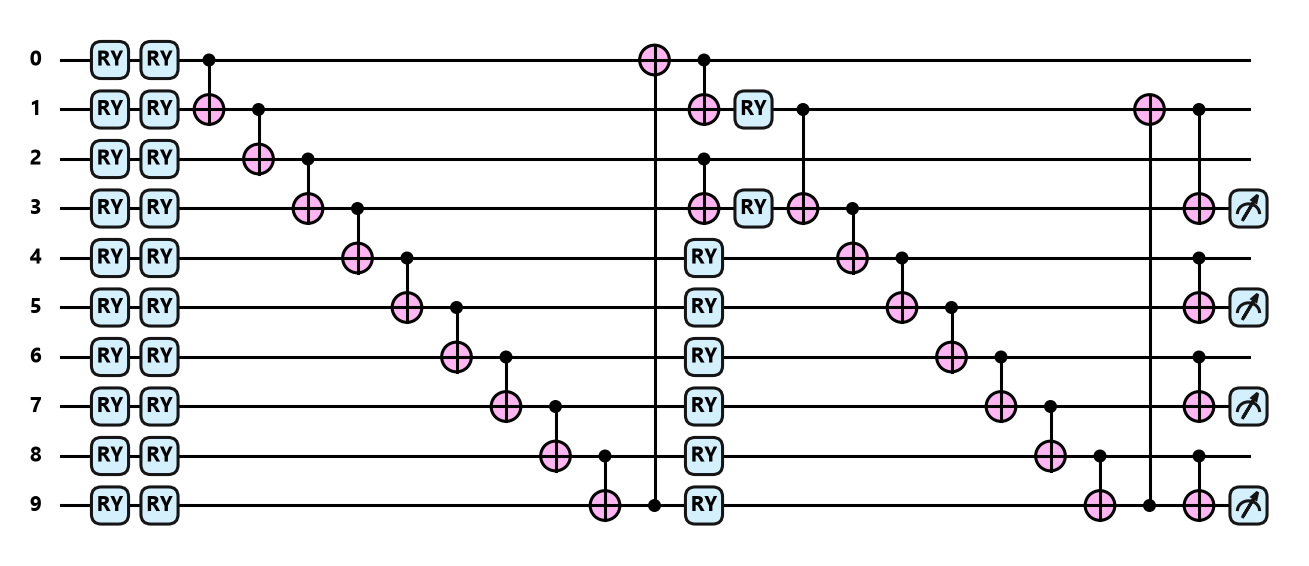

Parámetros entrenables de v1: 26


In [3]:
fig = figuras.circuito("qcnn_v1")
figuras.guardar(fig, "01_circuito_v1")
plt.show()
print(f"Parámetros entrenables de v1: {S['qcnn_v1'].n_parametros}")

## Resultados

Los controles de esta resolución ven exactamente los mismos 10 parches que v1:

- **CNN 10×10:** un filtro de 2×2 con paso 2 (equivale a procesar cada parche por separado), una capa densa de 10 unidades y la salida.
- **CPN 10×10** (*Classical Pyramid Network*): la misma topología que la QCNN sin estados cuánticos. Cada parche se reduce al valor normalizado de la capa de entrada, las convoluciones son $\tanh(x\,\theta)$ por posición, el pooling promedia pares y la pirámide termina en 4 valores con una capa lineal a 10 clases.

In [4]:
display(Markdown(res.tabla_markdown(S, ["qcnn_v1", "cnn_10", "cpn_10"])))

| Modelo | Parámetros | Accuracy de prueba (%) | Accuracy de entrenamiento (%) | Cómputo (h) |
| --- | ---: | ---: | ---: | ---: |
| QCNN v1 | 26 | 15,1 ± 10,7 | 15,3 ± 10,4 | 0,06 |
| CNN 10×10 | 225 | 59,9 ± 4,4 | 60,9 ± 4,3 | 0,01 |
| CPN 10×10 | 78 | 46,9 ± 0,8 | 46,9 ± 1,3 | 0,01 |

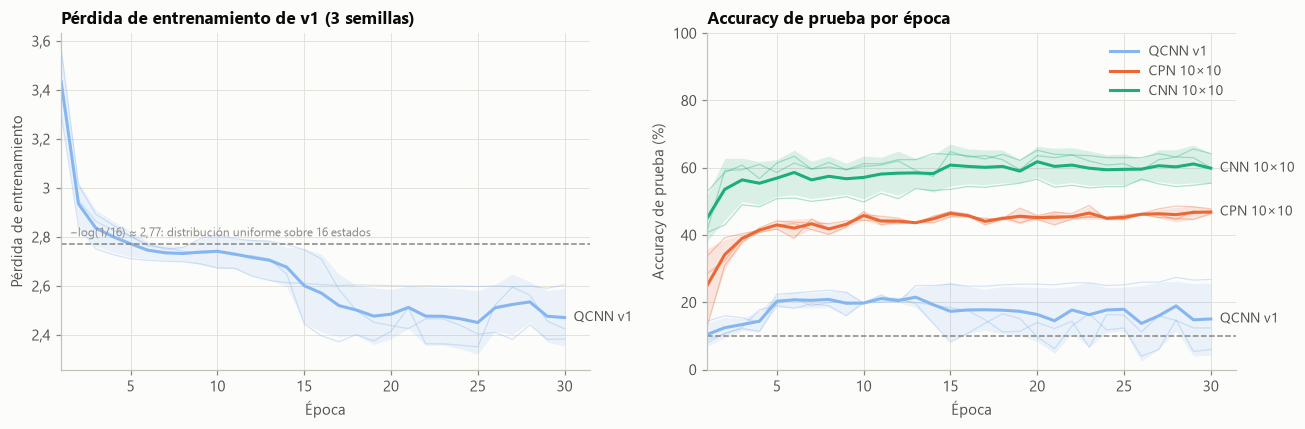

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
figuras.curvas(ax1, R, ["qcnn_v1"], "perdida_train")
ax1.axhline(np.log(16), color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax1.text(1.5, np.log(16) + 0.03, "−log(1/16) ≈ 2,77: distribución uniforme sobre 16 estados", fontsize=8, color=figuras.TINTA_TENUE)
ax1.set_title("Pérdida de entrenamiento de v1 (3 semillas)")
figuras.curvas(ax2, R, ["qcnn_v1", "cpn_10", "cnn_10"], "acc_test_por_epoca")
ax2.axhline(100 * figuras.AZAR, color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax2.set_ylim(0, 100)
ax2.set_title("Accuracy de prueba por época")
fig.tight_layout()
figuras.guardar(fig, "01_curvas_v1")
plt.show()

In [6]:
v1 = R["qcnn_v1"]
perdida = res.serie(v1, "perdida_train").mean(0)
acc = res.serie(v1, "acc_test_por_epoca")
print("Pérdida media en las épocas 1, 10, 20 y 30:", " · ".join(res.num(perdida[e - 1], 2) for e in (1, 10, 20, 30)))
for c, fila in zip(v1, acc):
    predichas = np.array(c["matriz_confusion"]).sum(0)
    print(
        f"Semilla {c['semilla']}: accuracy final {res.pct(c['acc_test'])} %, "
        f"rango entre épocas {res.pct(fila.min())}–{res.pct(fila.max())} %, "
        f"clase más predicha {predichas.argmax()} ({predichas.max()} de {predichas.sum()} imágenes)"
    )

Pérdida media en las épocas 1, 10, 20 y 30: 3,43 · 2,74 · 2,48 · 2,47
Semilla 42: accuracy final 6,0 %, rango entre épocas 4,0–21,2 %, clase más predicha 0 (218 de 500 imágenes)
Semilla 43: accuracy final 12,4 %, rango entre épocas 6,6–20,4 %, clase más predicha 1 (430 de 500 imágenes)
Semilla 44: accuracy final 26,8 %, rango entre épocas 14,0–27,4 %, clase más predicha 3 (112 de 500 imágenes)


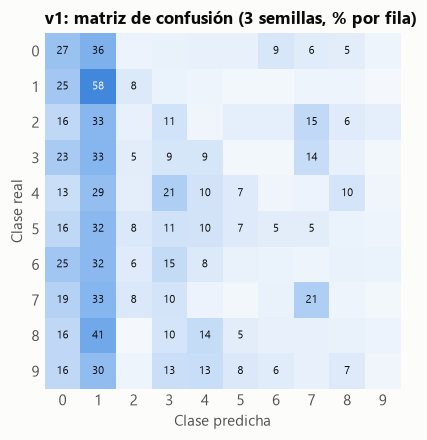

In [7]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
figuras.confusion(ax, v1, "v1: matriz de confusión (3 semillas, % por fila)")
figuras.guardar(fig, "01_confusion_v1")
plt.show()

## Lectura

- **v1 apenas aprende.** La pérdida pasa varias épocas cerca de −log(1/16), el valor que corresponde a repartir la probabilidad por igual entre los 16 estados; después baja un poco, pero la accuracy de prueba oscila de una época a otra y cambia mucho entre semillas. En alguna semilla el modelo termina asignando casi todas las imágenes a una sola clase.
- **La información está en los datos.** La CNN y la CPN, con los mismos 10 parches, superan con claridad a v1. El problema no es la entrada sino cómo la red la transforma y la lee.
- **Hipótesis para las siguientes versiones.** Hay dos candidatos: la poca expresividad del circuito (una rotación de un solo eje por qubit, 26 parámetros) y la lectura, que asigna cada clase a un estado base fijo y arbitrario de 4 qubits sin ninguna capa que pueda reordenar esa correspondencia. El notebook 02 ataca la primera; el 03, la segunda.